# 02 — A gravitational-wave-style whistle search

The whistle problem maps closely onto transient GW searches: a known *family* of signals (the
patterns) with unknown nuisance parameters (absolute pitch ≈ masses, tempo ≈ duration, start time),
buried in non-Gaussian, non-stationary noise full of glitches (speech, beeps). The whistle's phase is
not predictable, so we can't matched-filter the waveform; instead we stack **whitened power along a
time-frequency track** — the semi-coherent approach of burst searches like Wavegraph
([arXiv:1805.04023](https://arxiv.org/abs/1805.04023)) and CW HMM tracking
([arXiv:1606.02412](https://arxiv.org/abs/1606.02412)).

| GW pipeline | here |
|---|---|
| whitening by the noise PSD | each 25-cent frequency cell divided by its running ~3 s median power |
| template (CBC waveform) | piecewise-constant log-f track: note steps in semitones |
| intrinsic parameters | transposition, tempo, note-duration jitter |
| template bank, minimal match | rigid tracks over transposition × tempo (§4) |
| HMM/Viterbi frequency tracking | track search with free pitch, free dwell times (§3) |
| Allen χ² veto, re-weighted SNR | every note must carry an equal share of the score (§3) |
| time slides → FAR | shuffled 0.5 s chunks of non-whistle audio (§5) |
| injection campaigns → efficiency | whistles added to background at controlled SNR, 2-fold (§6) |

Code: `whistle_lab/search.py` (this notebook) and `whistle_lab/notes.py` (v1, notebook 01, used for comparison).
The web app's detector page (`detect.html`, `/api/detect`) runs the same Viterbi search.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from whistle_lab import notes as v1
from whistle_lab import search as gw

plt.rcParams.update({"figure.dpi": 80, "font.size": 9})
rng = np.random.default_rng(0)
recs = v1.load("../data/default")
whistles = [r for r in recs if r["label"] in v1.PATTERNS]
talking = [r["x"] for r in recs if r["label"] == "Talking"]
quiet = [r["x"] for r in recs if r["label"] == "Background noise"]
rms = lambda x: np.sqrt(np.mean(x ** 2))


def pink(n, seed=0):
    X = np.fft.rfft(np.random.default_rng(seed).standard_normal(n))
    X[1:] /= np.sqrt(np.arange(1, len(X)))
    x = np.fft.irfft(X, n)
    return x / rms(x)


def band_power(x):
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(len(x), 1 / gw.FS)
    return np.sum(np.abs(X[(f > gw.F_LO) & (f < gw.F_HI)]) ** 2) / len(x) ** 2

## 1. Whitened log-frequency spectrogram

STFT (1024-pt, 16 ms hop) → power on a 25-cent log grid from 700 Hz to 4 kHz (121 cells: musical
intervals become fixed cell offsets) → divide each cell by its running median over ~3 s. Under
stationary noise every cell then has median z = 1 regardless of colour or level: a whistle is judged
against *the noise at its own frequency*, which is what lets it sit on top of a TV or a kettle.

**Gating.** Whitening in time alone fails on non-stationary bursts: a loud chunk after a quiet one
lifts z in *every* cell, and a first version of this search happily drew tracks through such
broadband glitches (loudest background ρ̂ ≈ 230, comparable to real whistles; median z across
frequency on those frames 10–90). GW pipelines gate loud broadband glitches; the cheap analogue here
is to also divide each frame by its median z across frequency whenever that exceeds 1. A tone stays
far above its frame's median; a broadband burst doesn't.

Below: a whistle mixed with pink noise and speech at roughly 0 dB band SNR, before and after.

band SNR of this mix: -1.8 dB


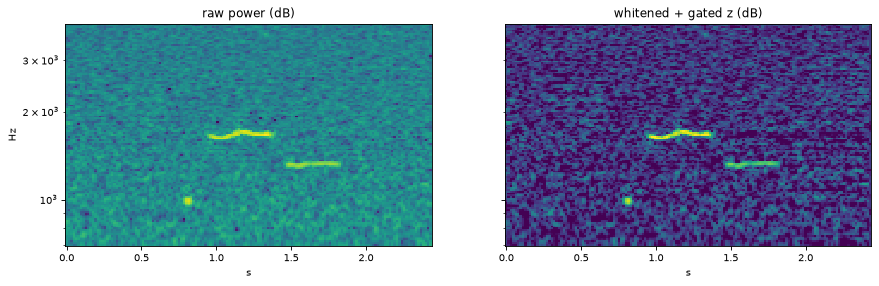

In [2]:
w = whistles[0]["x"]
noise = pink(len(w), 1) * 3 * rms(w) + np.resize(talking[1], len(w)) * 0.7
mix = w + noise
P = gw.to_log_grid(gw.spectrogram(mix))
_, z = gw.pixel_score(mix)
t = np.arange(len(P)) * gw.DT
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
axes[0].pcolormesh(t, gw.GRID_HZ, 10 * np.log10(P.T), shading="auto")
axes[0].set_title("raw power (dB)")
axes[1].pcolormesh(t, gw.GRID_HZ, 10 * np.log10(z.T), shading="auto", vmin=-5, vmax=25)
axes[1].set_title("whitened + gated z (dB)")
for ax in axes:
    ax.set_yscale("log"); ax.set_xlabel("s")
axes[0].set_ylabel("Hz")
print(f"band SNR of this mix: {10 * np.log10(band_power(w) / band_power(noise)):.1f} dB")

**Pixel score.** s = ln z − 2, floored at ln z = −1. A noise pixel costs about 2; a whistle pixel
40 dB above its local floor earns ≈ +7. Tracks therefore only accumulate score where there is real,
sustained excess power, and a track that runs through noise is actively penalised. (The floor stops a
single dropout frame destroying a real track.)

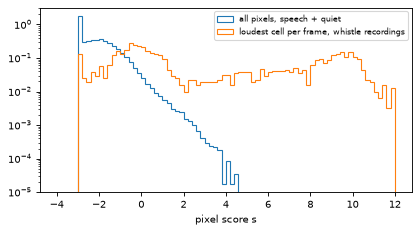

In [3]:
s_noise, _ = gw.pixel_score(np.concatenate(talking + quiet))
s_w = np.concatenate([gw.pixel_score(r["x"])[0].max(1) for r in whistles])
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(s_noise.ravel(), bins=80, range=(-4, 12), density=True, histtype="step", label="all pixels, speech + quiet")
ax.hist(s_w, bins=80, range=(-4, 12), density=True, histtype="step", label="loudest cell per frame, whistle recordings")
ax.set_yscale("log"); ax.set_xlabel("pixel score s"); ax.legend(fontsize=7)

## 2. Templates

From the v1 note extraction: median step (semitones) and median note durations per pattern. In §6
these are rebuilt per fold so the injected whistles never contributed to their own template.

In [4]:
def make_templates(recs_):
    tpl, dur = {}, {}
    for label in v1.PATTERNS:
        evs = [ev for r in recs_ if r["label"] == label for ev in v1.device_events(r["x"])]
        tpl[label] = np.median([v1.intervals(ev) for ev in evs], axis=0)
        dur[label] = np.median([[n.dur for n in ev] for ev in evs], axis=0)
    return tpl, dur

TPL, DUR = make_templates(recs)
for l in v1.PATTERNS:
    print(f"{l:10s} steps {np.round(TPL[l], 2)} st   durations {np.round(DUR[l], 2)} s")

Lights on  steps [ 9.46 -3.66] st   durations [0.27 0.56 0.45] s
Lights off steps [-4.4  -4.55] st   durations [0.25 0.28 0.54] s


## 3. Viterbi track search (the CW-style HMM)

Hidden state = (note k, frames spent in note, frequency cell). Transition log-probabilities:

- within a note the pitch may drift ±1 cell (25 cents) per frame, at a cost of 3 per cell — whistles
  are flat, so a path can't slide along a held note to wherever it would like to be;
- after ≥ 6 frames (~100 ms) the path may jump to the next note, by the template step ± 1.5
  semitones, with a Gaussian cost (σ = 0.5 st);
- note 0 may start in any cell at any frame (**free transposition and start time**), and dwell times
  are unconstrained above the minimum (**free tempo**) — so no bank is needed over those parameters.

The detection statistic at each frame is the score of the best *completed* path ending there.

**χ² veto.** Without it the wrong template scored 70–90 % of the right one: it matches two notes
perfectly and squeezes the third into 6 frames of nothing. Following Allen
([gr-qc/0405045](https://arxiv.org/abs/gr-qc/0405045)), split the template into bins of *equal
expected contribution* — here, notes, compared by mean score per frame — and measure the spread:
χ² = mean_k (m_k / m̄ − 1)². Then re-weight as PyCBC does:
ρ̂ = S · [(1 + (χ²/χ₀)³)/2]^(−1/6) when χ² > χ₀.

/home/claude/whistle-detection/src/whistle_lab/search.py:82: RuntimeWarning: invalid value encountered in multiply
  return np.where(self.score > 0, self.score * factor, self.score)


recording                  ρ̂ on  χ² on  ρ̂ off χ² off
Lights on   49b957           566   0.06     249   0.51
Lights on   2c8919           193   0.34     141   0.66
Lights on   480337           634   0.01     235   0.56
Lights on   2069eb           738   0.02     249   0.58
Lights on   5fa7e2           863   0.02     330   0.64
Lights off  28fe22            77   1.10     415   0.03
Lights off  17f2fc           143   1.16     563   0.03
Lights off  c2e217            59   1.14     283   0.01
Lights off  fbfe88           310   1.14    1100   0.01


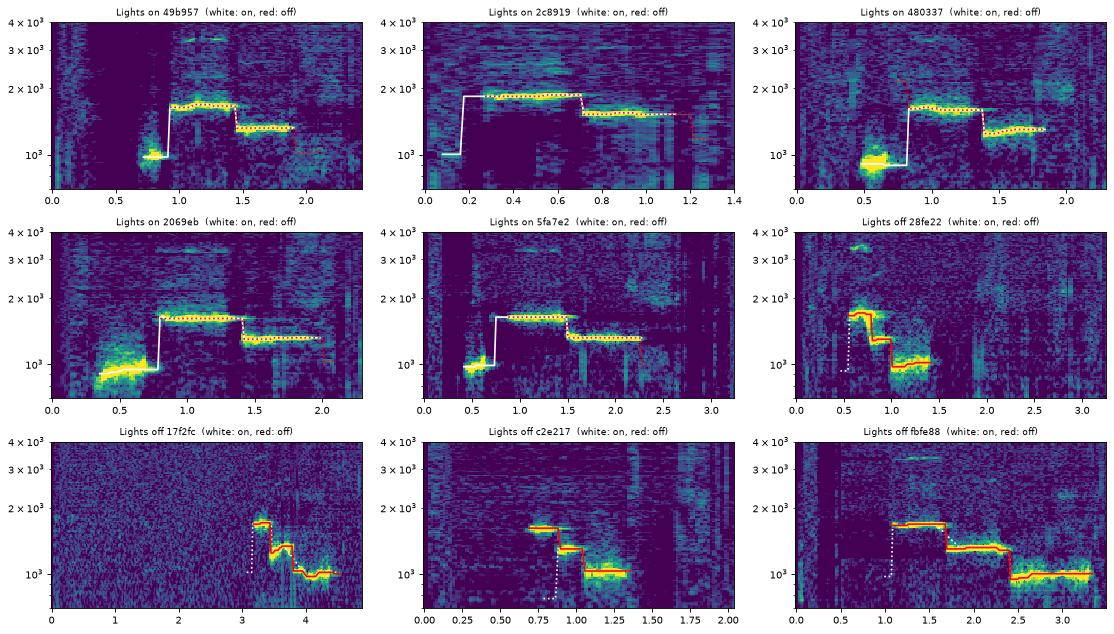

In [5]:
CHI0 = 0.1

fig, axes = plt.subplots(3, 3, figsize=(14, 8))
rows = []
for ax, r in zip(axes.ravel(), whistles):
    s, z = gw.pixel_score(r["x"])
    t = np.arange(len(s)) * gw.DT
    ax.pcolormesh(t, gw.GRID_HZ, 10 * np.log10(z.T), shading="auto", vmin=-5, vmax=30)
    res = {}
    for label, c in zip(v1.PATTERNS, ["w", "r"]):
        tr = gw.viterbi(s, TPL[label], keep_path=True)
        rw = tr.reweighted(CHI0)
        b = int(np.argmax(rw))
        fr, cells, _ = tr.path(b)
        ax.plot(fr * gw.DT, gw.GRID_HZ[cells], c, lw=1.5, ls="-" if label == r["label"] else ":")
        res[label] = (rw[b], tr.chisq()[b])
    rows.append((r["label"], r["id"][-6:], res))
    ax.set_yscale("log"); ax.set_ylim(700, 4000)
    ax.set_title(f'{r["label"]} {r["id"][-6:]}  (white: on, red: off)', fontsize=8)
fig.tight_layout()

print(f"{'recording':24s}{'ρ̂ on':>8s}{'χ² on':>7s}{'ρ̂ off':>8s}{'χ² off':>7s}")
for label, rid, res in rows:
    print(f"{label:12s}{rid:12s}{res['Lights on'][0]:8.0f}{res['Lights on'][1]:7.2f}"
          f"{res['Lights off'][0]:8.0f}{res['Lights off'][1]:7.2f}")

Solid line: the correct template's best track, dotted: the other template. The correct template wins
every recording by a wide margin once the χ² is applied.

## 4. Stacked-power template bank (the CBC-style search)

Rigid tracks: fixed note-duration *ratios* from the template, a grid of 11 tempo scales (0.5–2×), all
121 transpositions, ±1 cell track width; the score of each (template, end frame) is the summed pixel
score, re-weighted by the same χ². Per end-frame the best template is kept, as a CBC pipeline
clusters over its bank. Fast (cumulative sums), but it assumes your rhythm is consistent.

In [6]:
print(f"{'recording':24s}{'ρ̂ on':>8s}{'ρ̂ off':>8s}")
for r in whistles + [r for r in recs if r["label"] not in v1.PATTERNS]:
    s, _ = gw.pixel_score(r["x"])
    out = [gw.bank(s, TPL[l], DUR[l], CHI0).reweighted(CHI0).max() for l in v1.PATTERNS]
    print(f'{r["label"]:12s}{r["id"][-6:]:12s}{out[0]:8.0f}{out[1]:8.0f}')

recording                  ρ̂ on  ρ̂ off
Lights on   49b957           537     158
Lights on   2c8919           107      76
Lights on   480337           635     142
Lights on   2069eb           719     120
Lights on   5fa7e2           814     199
Lights off  28fe22            76     427


Lights off  17f2fc           125     566
Lights off  c2e217            44     225
Lights off  fbfe88           200     965
Background noise6e4d36           -21     -15


Background noise1918a9           -21     -21
Background noise7b536a           -19     -15
Talking     3a7586           -18       0


Talking     ce1ac3             2      11
Talking     d19542           -15      -1


## 5. Background and false-alarm rate

GW searches measure their false-alarm rate empirically from time slides. With one microphone there
is nothing to slide against, so a surrogate: cut all non-whistle audio into 0.5 s chunks (longer than
a note, shorter than a pattern) and splice random chunks together. Pool: speech pitch-shifted by
0…+24 semitones (stand-in for higher voices), the quiet room, pink noise, and speech + pink.

⚠️ The pool is only ~40 s of real audio, so this background is highly repetitive and contains no
beeps, music, TV or real high voices. Treat the FAR numbers as a test of the machinery, not of the
real household.

viterbi  loudest background trigger ρ̂ = 88   (322 triggers with ρ̂ > 0 in 30 min)
bank     loudest background trigger ρ̂ = 43   (191 triggers with ρ̂ > 0 in 30 min)
v1       server matches in background: 0   device forwards: 0


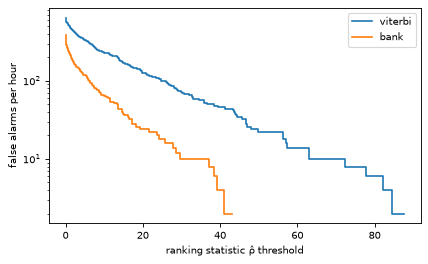

In [7]:
pool = [v1.pitch_shift(x, st) for x in talking for st in (0, 5, 7, 12, 15, 19, 24)]
pool += quiet
level = np.median([rms(x) for x in talking])
pool += [pink(10 * gw.FS, seed=i) * level for i in range(3)]
pool += [x + pink(len(x), seed=10 + i) * level for i, x in enumerate(talking)]

BG_S = 1800
bg = gw.shuffled_background(pool, BG_S, seed=1)
s_bg, _ = gw.pixel_score(bg)
methods = {
    "viterbi": {l: (lambda s, l=l, tpl=TPL: gw.viterbi(s, tpl[l])) for l in v1.PATTERNS},
    "bank": {l: (lambda s, l=l, tpl=TPL, dur=DUR: gw.bank(s, tpl[l], dur[l], CHI0)) for l in v1.PATTERNS},
}
bg_trig = {}
for name, runners in methods.items():
    stat, lab, _ = gw.search(s_bg, runners, CHI0)
    bg_trig[name] = gw.triggers(stat, lab, height=0)[1]

v1_tpl = v1.build_templates(recs)
v1_bg = [l for l in v1.detect(bg, v1_tpl) if l in v1.PATTERNS]
v1_fwd = len(v1.device_events(bg))

fig, ax = plt.subplots(figsize=(6, 3.5))
for name, vals in bg_trig.items():
    v = np.sort(vals)[::-1]
    ax.step(v, np.arange(1, len(v) + 1) / (BG_S / 3600), where="post", label=name)
ax.set_yscale("log"); ax.set_xlabel("ranking statistic ρ̂ threshold"); ax.set_ylabel("false alarms per hour")
ax.legend()
for name, vals in bg_trig.items():
    print(f"{name:8s} loudest background trigger ρ̂ = {vals.max():.0f}   ({len(vals)} triggers with ρ̂ > 0 in {BG_S / 60:.0f} min)")
print(f"v1       server matches in background: {len(v1_bg)}   device forwards: {v1_fwd}")

## 6. Injections and detection efficiency

2-fold: templates (steps and durations) are built from one half of the whistle recordings and the
other half are injected, then swapped. Each whistle is cropped to its event, scaled to a target
**band SNR** (700–4000 Hz power of the whistle over its duration ÷ background band power) and added
at 6 s spacing into a fresh shuffled background, 3 times each. A detection is a trigger of the
correct pattern, within the injection window, above the threshold set by the loudest background
trigger (i.e. FAR < 1 per 30 min of this background). Triggers are clustered over 2.5 s (one
pattern length), keeping the loudest across both patterns. The v1 detector runs on the same streams.

SNR(dB)    viterbi      bank        v1   wrong-label (v,b,v1)
   -12        0.00      0.00      0.04   0,0,0
    -9        0.22      0.19      0.15   0,0,0
    -6        0.26      0.19      0.22   2,0,0
    -3        0.48      0.33      0.33   0,0,0
    +0        0.41      0.26      0.33   0,0,0
    +3        0.67      0.59      0.44   2,1,0
    +6        0.89      0.67      0.70   0,0,0
    +9        0.96      0.81      0.81   0,1,0
   +12        1.00      0.85      0.85   0,2,0
   +15        1.00      0.96      0.81   0,0,0
   +18        1.00      1.00      0.81   0,0,0


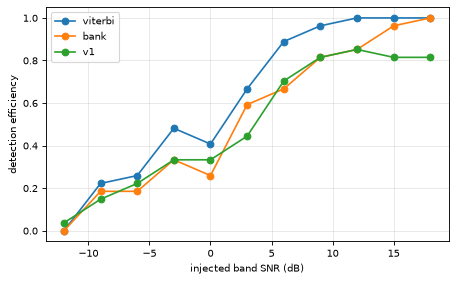

In [8]:
def snippet(r):
    ev = v1.device_events(r["x"])[0]
    a, b = int((ev[0].start - 0.1) * gw.FS), int((ev[-1].end + 0.1) * gw.FS)
    x = r["x"][max(a, 0):b].copy()
    ramp = np.linspace(0, 1, 160)
    x[:160] *= ramp; x[-160:] *= ramp[::-1]
    return x

folds = [[r for i, r in enumerate(whistles) if i % 2 == f] for f in (0, 1)]
SNRS = np.arange(-12, 21, 3)
REPEATS, SPACING = 3, 6.0
thr = {name: vals.max() for name, vals in bg_trig.items()}
eff = {m: np.zeros(len(SNRS)) for m in ["viterbi", "bank", "v1"]}
wrong = {m: np.zeros(len(SNRS)) for m in eff}
n_inj = np.zeros(len(SNRS))

for fi, test in enumerate(folds):
    train = [r for r in recs if r not in test]
    tpl_f, dur_f = make_templates(train)
    runners = {
        "viterbi": {l: (lambda s, l=l: gw.viterbi(s, tpl_f[l])) for l in v1.PATTERNS},
        "bank": {l: (lambda s, l=l: gw.bank(s, tpl_f[l], dur_f[l], CHI0)) for l in v1.PATTERNS},
    }
    v1_tpl_f = v1.build_templates(train)
    snips = [(r["label"], snippet(r)) for r in test for _ in range(REPEATS)]
    for si, snr in enumerate(SNRS):
        stream = gw.shuffled_background(pool, SPACING * (len(snips) + 1), seed=100 + 10 * fi + si)
        bgp = band_power(stream)
        truth = []
        for i, (label, x) in enumerate(snips):
            a = int((i + 0.5) * SPACING * gw.FS)
            stream[a:a + len(x)] += x * np.sqrt(bgp * 10 ** (snr / 10) / band_power(x))
            truth.append((label, a / gw.FS, (a + len(x)) / gw.FS))
        n_inj[si] += len(truth)
        s, _ = gw.pixel_score(stream)
        found = {}
        for name, rn in runners.items():
            stat, lab, _ = gw.search(s, rn, CHI0)
            pk, val, lb = gw.triggers(stat, lab, height=thr[name])
            found[name] = [(pk[i] * gw.DT, v1.PATTERNS[lb[i]]) for i in range(len(pk))]
        found["v1"] = []
        for ev in v1.device_events(stream):
            label, _ = v1.server_match(ev, v1_tpl_f)
            if label:
                found["v1"].append((ev[-1].end, label))
        for name, trig in found.items():
            for label, t0, t1 in truth:
                hits = [l for t, l in trig if t0 <= t <= t1 + 0.3]
                eff[name][si] += label in hits
                wrong[name][si] += any(h != label for h in hits)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name in eff:
    ax.plot(SNRS, eff[name] / n_inj, "o-", label=name)
ax.set_xlabel("injected band SNR (dB)"); ax.set_ylabel("detection efficiency"); ax.legend()
ax.grid(alpha=0.3)
print("SNR(dB) " + "".join(f"{m:>10s}" for m in eff) + "   wrong-label (v,b,v1)")
for si, snr in enumerate(SNRS):
    print(f"{snr:+6d}  " + "".join(f"{eff[m][si] / n_inj[si]:10.2f}" for m in eff)
          + f"   {int(wrong['viterbi'][si])},{int(wrong['bank'][si])},{int(wrong['v1'][si])}")

## 7. Notes

**Device cost.** The Viterbi recursion has 3 notes × 6 dwell states × 121 cells ≈ 2200 states with
≤ 9 candidate predecessors each: ~20k max-plus operations per 16 ms frame (~1.3 M/s) plus a
1024-point FFT. That fits comfortably on an ESP32-S3, so the *whole* search could run on the device
with the server only re-checking. Whitening needs a running per-cell median; on the device a
streaming quantile tracker (nudge each estimate up/down by a small step) replaces the exact median.

**Next:**
- Real background: hours of the room (TV, music, kitchen, other people) — the FAR here is an
  upper bound on what this tiny pool can tell us.
- Microstructure and 2nd-harmonic vetoes as extra signal-based vetoes (see `future-ideas`).
- Tune χ₀, drift cost and step σ on more examples; record more patterns to see how template
  separation behaves as the bank grows.